In [9]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0002.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0003.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0004.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0005.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0006.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0007.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0008.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0009.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0002.mp4
/kaggle/input/

In [10]:
import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/reubensuju/celeb-df-v2"

# Label mapping
labels = {
    "Celeb-real": 0,
    "YouTube-real": 0,
    "Celeb-synthesis": 1
}

video_data = []

for folder, label in labels.items():

    folder_path = os.path.join(DATASET_PATH, folder)

    if not os.path.exists(folder_path):
        print("Folder not found:", folder_path)
        continue

    for file in os.listdir(folder_path):

        if file.lower().endswith(".mp4"):

            video_data.append({
                "video_path": os.path.join(folder_path, file),
                "folder": folder,
                "label": label,
                "class": "Real" if label == 0 else "Fake"
            })

# Create DataFrame
df = pd.DataFrame(video_data)

print("Total Videos:", len(df))
print("\nClass Distribution:")
print(df["class"].value_counts())

df.head()

Total Videos: 6529

Class Distribution:
class
Fake    5639
Real     890
Name: count, dtype: int64


,video_path,folder,label,class
0,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
1,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
2,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
3,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
4,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real


In [11]:
OUTPUT_PATH = "/kaggle/working/dataset_manifest.csv"

df.to_csv(OUTPUT_PATH, index=False)

print("Dataset manifest saved!")
print("Location:", OUTPUT_PATH)

Dataset manifest saved!
Location: /kaggle/working/dataset_manifest.csv


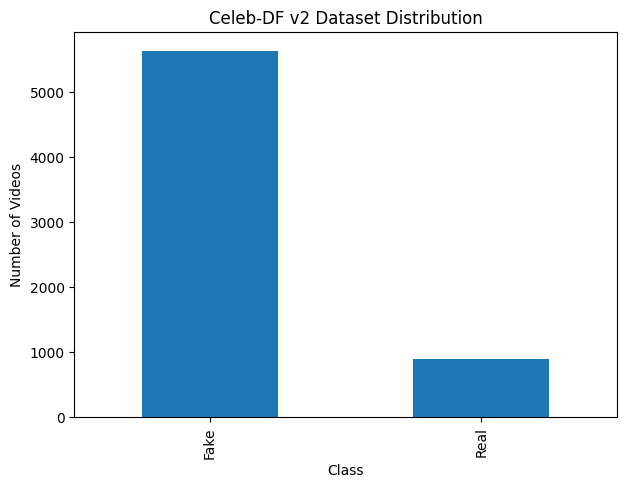

In [13]:
import matplotlib.pyplot as plt

df["class"].value_counts().plot(
    kind="bar",
    figsize=(7, 5),
    title="Celeb-DF v2 Dataset Distribution"
)

plt.xlabel("Class")
plt.ylabel("Number of Videos")
plt.show()

In [14]:
import os
import glob

# Find official testing list
list_files = glob.glob(
    "/kaggle/input/**/List_of_testing_videos.txt",
    recursive=True
)

if list_files:

    TEST_LIST_PATH = list_files[0]

    print("Official test list found!")
    print("Location:", TEST_LIST_PATH)

    with open(TEST_LIST_PATH, "r") as f:
        test_lines = [line.strip() for line in f if line.strip()]

    print("Total entries:", len(test_lines))

    print("\nFirst 10 entries:")

    for line in test_lines[:10]:
        print(line)

else:
    print("Official test list not found!")

Official test list found!
Location: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
Total entries: 518

First 10 entries:
1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4


In [15]:
print("Total videos:", len(df))

print("\nDataset columns:")
print(df.columns.tolist())

print("\nSample records:")
display(df.head())

print("\nVideos by folder:")
print(df["folder"].value_counts())

Total videos: 6529

Dataset columns:
['video_path', 'folder', 'label', 'class']

Sample records:


,video_path,folder,label,class
0,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
1,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
2,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
3,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
4,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real



Videos by folder:
folder
Celeb-synthesis    5639
Celeb-real          590
YouTube-real        300
Name: count, dtype: int64


In [16]:
import os
import glob

# Search for official testing list
test_files = glob.glob(
    "/kaggle/input/**/List_of_testing_videos.txt",
    recursive=True
)

print("Official Testing List Search")

if test_files:

    TEST_LIST_PATH = test_files[0]

    print("Testing list found!")
    print("Path:", TEST_LIST_PATH)

    with open(TEST_LIST_PATH, "r") as f:
        test_videos = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Total test entries:", len(test_videos))

    print("\nFirst 10 entries:")

    for video in test_videos[:10]:
        print(video)

else:
    print("Official testing list not found.")

# Inspect video filenames
print("\nSample video filenames:")

for folder in ["Celeb-real", "YouTube-real", "Celeb-synthesis"]:

    sample = df[df["folder"] == folder]["video_path"].head(5)

    print("\n", folder)

    for path in sample:
        print(os.path.basename(path))

Official Testing List Search
Testing list found!
Path: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
Total test entries: 518

First 10 entries:
1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4

Sample video filenames:

 Celeb-real
id0_0000.mp4
id0_0001.mp4
id0_0002.mp4
id0_0003.mp4
id0_0004.mp4

 YouTube-real
00000.mp4
00001.mp4
00002.mp4
00003.mp4
00004.mp4

 Celeb-synthesis
id0_id16_0000.mp4
id0_id16_0001.mp4
id0_id16_0002.mp4
id0_id16_0003.mp4
id0_id16_0004.mp4


In [17]:
import os
import pandas as pd

print("========== DATASET QUALITY CHECK ==========")

# 1. Total videos
print("\nTotal videos:", len(df))

# 2. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 3. Check whether video files exist
missing_files = [
    path for path in df["video_path"]
    if not os.path.isfile(path)
]

print("\nMissing video files:", len(missing_files))

# 4. Check duplicate paths
duplicates = df["video_path"].duplicated().sum()

print("Duplicate video paths:", duplicates)

# 5. Verify labels
expected_labels = {
    "Celeb-real": 0,
    "YouTube-real": 0,
    "Celeb-synthesis": 1
}

df["expected_label"] = df["folder"].map(expected_labels)

incorrect_labels = (
    df["label"] != df["expected_label"]
).sum()

print("Incorrect labels:", incorrect_labels)

# 6. Class distribution
print("\nClass Distribution:")
print(df["class"].value_counts())

print("\n========== CHECK COMPLETED ==========")

========== DATASET QUALITY CHECK ==========

Total videos: 6529

Missing values:
video_path    0
folder        0
label         0
class         0
dtype: int64

Missing video files: 0
Duplicate video paths: 0
Incorrect labels: 0

Class Distribution:
class
Fake    5639
Real     890
Name: count, dtype: int64

========== CHECK COMPLETED ==========


In [18]:
import cv2
import random
import os

print("========== VIDEO READABILITY TEST ==========")

for folder in ["Celeb-real", "YouTube-real", "Celeb-synthesis"]:

    samples = df[df["folder"] == folder].sample(
        n=min(3, len(df[df["folder"] == folder])),
        random_state=42
    )

    print("\nTesting:", folder)

    for _, row in samples.iterrows():

        path = row["video_path"]

        cap = cv2.VideoCapture(path)

        success, frame = cap.read()

        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        if success:
            print(
                os.path.basename(path),
                "| Readable: YES",
                "| Frames:", total_frames,
                "| FPS:", round(fps, 2)
            )
        else:
            print(
                os.path.basename(path),
                "| Readable: NO"
            )

        cap.release()

print("\n========== TEST COMPLETED ==========")

========== VIDEO READABILITY TEST ==========

Testing: Celeb-real
id5_0002.mp4 | Readable: YES | Frames: 534 | FPS: 30.0
id37_0005.mp4 | Readable: YES | Frames: 458 | FPS: 30.0
id59_0004.mp4 | Readable: YES | Frames: 380 | FPS: 30.0

Testing: YouTube-real
00203.mp4 | Readable: YES | Frames: 309 | FPS: 30.0
00266.mp4 | Readable: YES | Frames: 329 | FPS: 30.0
00152.mp4 | Readable: YES | Frames: 698 | FPS: 30.0

Testing: Celeb-synthesis
id29_id30_0005.mp4 | Readable: YES | Frames: 468 | FPS: 30.0
id26_id19_0003.mp4 | Readable: YES | Frames: 249 | FPS: 30.0
id39_id42_0000.mp4 | Readable: YES | Frames: 321 | FPS: 30.0

========== TEST COMPLETED ==========


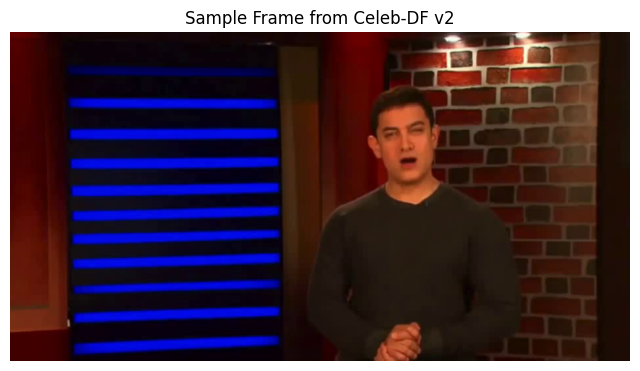

In [19]:
import matplotlib.pyplot as plt
import cv2

sample_path = df.iloc[0]["video_path"]

cap = cv2.VideoCapture(sample_path)

success, frame = cap.read()

cap.release()

if success:

    frame = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(8, 5))
    plt.imshow(frame)
    plt.title("Sample Frame from Celeb-DF v2")
    plt.axis("off")
    plt.show()

else:
    print("Unable to read video.")

In [1]:
import os
import glob

# Search for the official test list
test_files = glob.glob(
    "/kaggle/input/**/List_of_testing_videos.txt",
    recursive=True
)

if test_files:

    TEST_LIST_PATH = test_files[0]

    print("Official Testing List Found!")
    print("Path:", TEST_LIST_PATH)

    with open(TEST_LIST_PATH, "r") as f:
        test_videos = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Total test entries:", len(test_videos))

    print("\nFirst 10 entries:")

    for video in test_videos[:10]:
        print(video)

else:
    print("Official testing list not found in this dataset.")

Official Testing List Found!
Path: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
Total test entries: 518

First 10 entries:
1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4


In [4]:
import os

for folder in [
    "Celeb-real",
    "YouTube-real",
    "Celeb-synthesis"
]:

    print("\n==========", folder, "==========")

    sample_videos = (
        df[df["folder"] == folder]["video_path"]
        .head(10)
    )

    for path in sample_videos:
        print(os.path.basename(path))


========== Celeb-real ==========
id0_0000.mp4
id0_0001.mp4
id0_0002.mp4
id0_0003.mp4
id0_0004.mp4
id0_0005.mp4
id0_0006.mp4
id0_0007.mp4
id0_0008.mp4
id0_0009.mp4

========== YouTube-real ==========
00000.mp4
00001.mp4
00002.mp4
00003.mp4
00004.mp4
00005.mp4
00006.mp4
00007.mp4
00008.mp4
00009.mp4

========== Celeb-synthesis ==========
id0_id16_0000.mp4
id0_id16_0001.mp4
id0_id16_0002.mp4
id0_id16_0003.mp4
id0_id16_0004.mp4
id0_id16_0005.mp4
id0_id16_0006.mp4
id0_id16_0007.mp4
id0_id16_0008.mp4
id0_id16_0009.mp4


In [3]:
import os
import pandas as pd

DATASET_PATH = "/kaggle/input/datasets/reubensuju/celeb-df-v2"

labels = {
    "Celeb-real": 0,
    "YouTube-real": 0,
    "Celeb-synthesis": 1
}

video_data = []

for root, dirs, files in os.walk(DATASET_PATH):

    folder_name = os.path.basename(root)

    if folder_name in labels:

        for file in files:

            if file.lower().endswith(".mp4"):

                label = labels[folder_name]

                video_data.append({
                    "video_path": os.path.join(root, file),
                    "folder": folder_name,
                    "label": label,
                    "class": "Real" if label == 0 else "Fake"
                })

if not video_data:
    raise FileNotFoundError(
        "Dataset not found. Check whether Celeb-DF v2 is attached."
    )

df = pd.DataFrame(video_data)

print("Dataset Loaded Successfully!")
print("Total Videos:", len(df))

print("\nClass Distribution:")
print(df["class"].value_counts())

display(df.head())

Dataset Loaded Successfully!
Total Videos: 6529

Class Distribution:
class
Fake    5639
Real     890
Name: count, dtype: int64


,video_path,folder,label,class
0,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
1,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
2,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
3,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real
4,/kaggle/input/datasets/reubensuju/celeb-df-v2/...,Celeb-real,0,Real


In [5]:
import os
import glob

# Search for official testing list
test_files = glob.glob(
    "/kaggle/input/**/List_of_testing_videos.txt",
    recursive=True
)

if test_files:
    TEST_LIST_PATH = test_files[0]

    print("Official Testing List Found!")
    print("Path:", TEST_LIST_PATH)

    with open(TEST_LIST_PATH, "r") as f:
        test_lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Total test entries:", len(test_lines))

    print("\nFirst 10 entries:")

    for line in test_lines[:10]:
        print(line)

else:
    print("Official testing list not found!")

Official Testing List Found!
Path: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
Total test entries: 518

First 10 entries:
1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4


In [6]:
import os
import pandas as pd

if "df" not in globals():
    raise NameError("Please recreate the dataset DataFrame first.")

if "TEST_LIST_PATH" not in globals():
    raise NameError("Run Step 1 first.")

test_records = []

for line in test_lines:

    parts = line.split(maxsplit=1)

    if len(parts) != 2:
        continue

    official_label = int(parts[0])
    relative_path = parts[1].replace("\\", "/")

    path_parts = relative_path.strip("/").split("/")

    folders = [
        "Celeb-real",
        "YouTube-real",
        "Celeb-synthesis"
    ]

    folder = next(
        (f for f in path_parts if f in folders),
        None
    )

    if folder is None:
        continue

    filename = path_parts[path_parts.index(folder) + 1]

    # Official labels: 1 = Real, 0 = Fake
    our_label = 0 if official_label == 1 else 1

    test_records.append({
        "folder": folder,
        "filename": filename,
        "official_label": official_label,
        "label": our_label
    })

official_test = pd.DataFrame(test_records)

# Match with existing dataset
df["filename"] = df["video_path"].apply(os.path.basename)

df["match_key"] = (
    df["folder"] + "/" + df["filename"]
)

official_test["match_key"] = (
    official_test["folder"] + "/" +
    official_test["filename"]
)

matched = official_test[
    official_test["match_key"].isin(df["match_key"])
]

print("Official test entries:", len(official_test))
print("Successfully matched:", len(matched))
print("Unmatched entries:", len(official_test) - len(matched))

print("\nOfficial Test Distribution:")
print(matched["label"].map({
    0: "Real",
    1: "Fake"
}).value_counts())

Official test entries: 518
Successfully matched: 518
Unmatched entries: 0

Official Test Distribution:
label
Fake    340
Real    178
Name: count, dtype: int64


In [7]:
total = len(df)

majority_count = df["label"].value_counts().max()

baseline_accuracy = (majority_count / total) * 100

print("Total Videos:", total)
print("Baseline Accuracy:", round(baseline_accuracy, 2), "%")

Total Videos: 6529
Baseline Accuracy: 86.37 %


In [1]:

import os
import glob

test_files = glob.glob(
    "/kaggle/input/**/List_of_testing_videos.txt",
    recursive=True
)

if test_files:
    TEST_LIST_PATH = test_files[0]

    print("Official test list found!")
    print("Path:", TEST_LIST_PATH)

    with open(TEST_LIST_PATH, "r") as f:
        test_lines = [line.strip() for line in f if line.strip()]

    print("\nTotal entries:", len(test_lines))
    print("\nFirst 15 entries:")

    for line in test_lines[:15]:
        print(line)

else:
    print("Official test list not found.")

    print("\nAvailable text files:")
    for path in glob.glob("/kaggle/input/**/*.txt", recursive=True):
        print(path)


Official test list found!
Path: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt

Total entries: 518

First 15 entries:
1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4
1 YouTube-real/00213.mp4
1 YouTube-real/00011.mp4
1 YouTube-real/00095.mp4
1 YouTube-real/00138.mp4
1 YouTube-real/00106.mp4


In [3]:
import os
import pandas as pd

# Dataset folder labels
labels = {
    "Celeb-real": 0,
    "YouTube-real": 0,
    "Celeb-synthesis": 1
}

video_data = []

# Scan the dataset
for root, dirs, files in os.walk("/kaggle/input"):

    folder_name = os.path.basename(root)

    if folder_name in labels:

        for file in files:

            if file.lower().endswith(".mp4"):

                label = labels[folder_name]

                video_data.append({
                    "video_path": os.path.join(root, file),
                    "folder": folder_name,
                    "label": label,
                    "class": "Real" if label == 0 else "Fake"
                })

# Create DataFrame
df = pd.DataFrame(video_data)

print("Dataset loaded successfully!")
print("Total videos:", len(df))
print("\nClass distribution:")
print(df["folder"].value_counts())

Dataset loaded successfully!
Total videos: 6529

Class distribution:
folder
Celeb-synthesis    5639
Celeb-real          590
YouTube-real        300
Name: count, dtype: int64


In [4]:
for folder in ["Celeb-real", "YouTube-real", "Celeb-synthesis"]:

    print("\n==========", folder, "==========")

    samples = df[df["folder"] == folder]["video_path"].head(10)

    for path in samples:
        print(os.path.basename(path))


========== Celeb-real ==========
id49_0006.mp4
id27_0008.mp4
id32_0000.mp4
id1_0006.mp4
id50_0006.mp4
id55_0006.mp4
id0_0005.mp4
id32_0008.mp4
id0_0008.mp4
id3_0008.mp4

========== YouTube-real ==========
00238.mp4
00152.mp4
00269.mp4
00209.mp4
00297.mp4
00096.mp4
00255.mp4
00230.mp4
00259.mp4
00012.mp4

========== Celeb-synthesis ==========
id33_id20_0005.mp4
id24_id19_0004.mp4
id0_id3_0009.mp4
id51_id50_0008.mp4
id54_id53_0003.mp4
id22_id19_0006.mp4
id52_id49_0008.mp4
id35_id4_0006.mp4
id52_id53_0003.mp4
id50_id52_0004.mp4


In [5]:
import os

print("Searching for official test list...\n")

found = False

for root, dirs, files in os.walk("/kaggle/input"):

    for file in files:

        if file.lower() == "list_of_testing_videos.txt":

            file_path = os.path.join(root, file)
            found = True

            print("File found:", file_path)

            with open(file_path, "r") as f:
                lines = f.readlines()

            print("Total entries:", len(lines))
            print("\nFirst 20 entries:\n")

            for line in lines[:20]:
                print(line.strip())

if not found:
    print("Official test list not found in the dataset.")

Searching for official test list...

File found: /kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
Total entries: 518

First 20 entries:

1 YouTube-real/00170.mp4
1 YouTube-real/00208.mp4
1 YouTube-real/00063.mp4
1 YouTube-real/00024.mp4
1 YouTube-real/00021.mp4
1 YouTube-real/00036.mp4
1 YouTube-real/00202.mp4
1 YouTube-real/00236.mp4
1 YouTube-real/00197.mp4
1 YouTube-real/00133.mp4
1 YouTube-real/00213.mp4
1 YouTube-real/00011.mp4
1 YouTube-real/00095.mp4
1 YouTube-real/00138.mp4
1 YouTube-real/00106.mp4
1 YouTube-real/00194.mp4
1 YouTube-real/00092.mp4
1 YouTube-real/00227.mp4
1 YouTube-real/00244.mp4
1 YouTube-real/00119.mp4


In [6]:
import os
import pandas as pd

# Official test-list location
test_file = "/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt"

# Read official test list
with open(test_file, "r") as f:
    test_lines = f.readlines()

# Extract video paths (ignore the first numeric column)
official_test_paths = []

for line in test_lines:
    parts = line.strip().split(maxsplit=1)

    if len(parts) == 2:
        official_test_paths.append(
            os.path.normpath(parts[1])
        )

# Match official paths with our DataFrame
df["relative_path"] = df["video_path"].apply(
    lambda x: os.path.normpath(
        os.path.relpath(
            x,
            "/kaggle/input/datasets/reubensuju/celeb-df-v2"
        )
    )
)

test_df = df[df["relative_path"].isin(official_test_paths)].copy()

# Remaining videos will be used for training and validation
train_val_df = df[
    ~df["relative_path"].isin(official_test_paths)
].copy()

# Display results
print("========== OFFICIAL TEST SET ==========")
print("Official test-list entries:", len(official_test_paths))
print("Matched test videos:", len(test_df))
print("\nTest set distribution:")
print(test_df["folder"].value_counts())

print("\n========== REMAINING DATA ==========")
print("Remaining videos:", len(train_val_df))
print("\nRemaining data distribution:")
print(train_val_df["folder"].value_counts())

# Check for unmatched paths
unmatched = set(official_test_paths) - set(test_df["relative_path"])

print("\nUnmatched official test paths:", len(unmatched))

if unmatched:
    print("First unmatched paths:")
    for path in list(unmatched)[:10]:
        print(path)

========== OFFICIAL TEST SET ==========
Official test-list entries: 518
Matched test videos: 518

Test set distribution:
folder
Celeb-synthesis    340
Celeb-real         108
YouTube-real        70
Name: count, dtype: int64

========== REMAINING DATA ==========
Remaining videos: 6011

Remaining data distribution:
folder
Celeb-synthesis    5299
Celeb-real          482
YouTube-real        230
Name: count, dtype: int64

Unmatched official test paths: 0


In [7]:
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
# Split remaining data into training and validation sets
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.20,
    random_state=42,
    stratify=train_val_df["folder"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Dataset splitting completed successfully!")

Dataset splitting completed successfully!


In [9]:
# Create binary labels
label_mapping = {
    "Celeb-real": 0,
    "YouTube-real": 0,
    "Celeb-synthesis": 1
}

train_df["label"] = train_df["folder"].map(label_mapping)
val_df["label"] = val_df["folder"].map(label_mapping)
test_df["label"] = test_df["folder"].map(label_mapping)

print("Labels assigned successfully!")

Labels assigned successfully!


In [10]:
print("========== TRAINING DATA ==========")
print("Total videos:", len(train_df))
print(train_df["folder"].value_counts())
print("\nReal/Fake distribution:")
print(train_df["label"].value_counts())

print("\n========== VALIDATION DATA ==========")
print("Total videos:", len(val_df))
print(val_df["folder"].value_counts())
print("\nReal/Fake distribution:")
print(val_df["label"].value_counts())

print("\n========== OFFICIAL TEST DATA ==========")
print("Total videos:", len(test_df))
print(test_df["folder"].value_counts())
print("\nReal/Fake distribution:")
print(test_df["label"].value_counts())

========== TRAINING DATA ==========
Total videos: 4808
folder
Celeb-synthesis    4238
Celeb-real          386
YouTube-real        184
Name: count, dtype: int64

Real/Fake distribution:
label
1    4238
0     570
Name: count, dtype: int64

========== VALIDATION DATA ==========
Total videos: 1203
folder
Celeb-synthesis    1061
Celeb-real           96
YouTube-real         46
Name: count, dtype: int64

Real/Fake distribution:
label
1    1061
0     142
Name: count, dtype: int64

========== OFFICIAL TEST DATA ==========
Total videos: 518
folder
Celeb-synthesis    340
Celeb-real         108
YouTube-real        70
Name: count, dtype: int64

Real/Fake distribution:
label
1    340
0    178
Name: count, dtype: int64


In [11]:
output_dir = "/kaggle/working/dataset_splits"

os.makedirs(output_dir, exist_ok=True)

train_df.to_csv(
    f"{output_dir}/train.csv", index=False
)

val_df.to_csv(
    f"{output_dir}/validation.csv", index=False
)

test_df.to_csv(
    f"{output_dir}/test.csv", index=False
)

print("All dataset splits saved successfully!")

All dataset splits saved successfully!


In [14]:
import sys
import numpy
import PIL
import torch
import torchvision

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Pillow:", PIL.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.1.3
Pillow: 13.0.0
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130


In [15]:
!pip install facenet-pytorch==2.6.0 --no-deps

  Using cached facenet_pytorch-2.6.0-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 14.1 MB/s  0:00:00m0:00:01


In [16]:
from facenet_pytorch import MTCNN

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mtcnn = MTCNN(
    keep_all=False,
    device=device,
    post_process=False,
    min_face_size=40
)

print("MTCNN imported successfully!")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

MTCNN imported successfully!
Device: cuda
GPU: Tesla T4


In [17]:
sample_video = train_df.iloc[0]["video_path"]

print("Selected video:", sample_video)

Selected video: /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis/id27_id25_0001.mp4


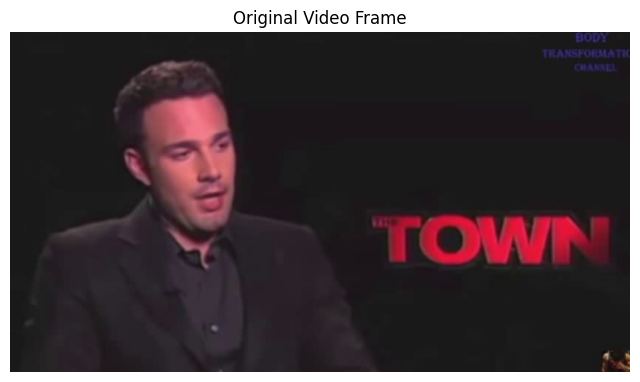

In [18]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(sample_video)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.set(cv2.CAP_PROP_POS_FRAMES, total_frames // 2)

ret, frame = cap.read()

cap.release()

if ret:
    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(rgb_frame)
    plt.axis("off")
    plt.title("Original Video Frame")
    plt.show()
else:
    print("Unable to read video!")

In [19]:


boxes, probabilities = mtcnn.detect(rgb_frame)

if boxes is not None and probabilities is not None:

    print("Face detected!")
    print("Bounding boxes:", boxes)
    print("Confidence:", probabilities)

else:
    print("No face detected in this frame.")

Face detected!
Bounding boxes: [[183.2852783203125 91.47540283203125 300.3152770996094 261.3504638671875]]
Confidence: [0.9999483823776245]


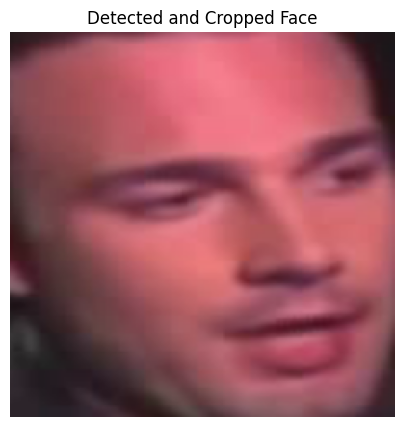

In [20]:
if boxes is not None:

    best_idx = probabilities.argmax()

    x1, y1, x2, y2 = boxes[best_idx].astype(int)

    h, w = rgb_frame.shape[:2]

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    face = rgb_frame[y1:y2, x1:x2]

    face = cv2.resize(face, (224, 224))

    plt.figure(figsize=(5, 5))
    plt.imshow(face)
    plt.axis("off")
    plt.title("Detected and Cropped Face")
    plt.show()

In [21]:
print("MTCNN:", mtcnn)
print("Device:", device)

MTCNN: MTCNN(
  (pnet): PNet(
    (conv1): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (prelu1): PReLU(num_parameters=10)
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv2): Conv2d(10, 16, kernel_size=(3, 3), stride=(1, 1))
    (prelu2): PReLU(num_parameters=16)
    (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
    (prelu3): PReLU(num_parameters=32)
    (conv4_1): Conv2d(32, 2, kernel_size=(1, 1), stride=(1, 1))
    (softmax4_1): Softmax(dim=1)
    (conv4_2): Conv2d(32, 4, kernel_size=(1, 1), stride=(1, 1))
  )
  (rnet): RNet(
    (conv1): Conv2d(3, 28, kernel_size=(3, 3), stride=(1, 1))
    (prelu1): PReLU(num_parameters=28)
    (pool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv2): Conv2d(28, 48, kernel_size=(3, 3), stride=(1, 1))
    (prelu2): PReLU(num_parameters=48)
    (pool2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=True)
    (conv3): Conv2d(

In [22]:
import os

output_dir = "/kaggle/working/processed_dataset"

for split in ["train", "validation", "test"]:
    for label in ["Real", "Fake"]:
        os.makedirs(
            os.path.join(output_dir, split, label),
            exist_ok=True
        )

print("Dataset folders created successfully!")

Dataset folders created successfully!


In [30]:
import os
import cv2
import torch
import pandas as pd
from facenet_pytorch import MTCNN
from tqdm import tqdm

# 1. Device configuration (Leverages Kaggle's Tesla T4 GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Initialize MTCNN
mtcnn = MTCNN(
    keep_all=False,
    device=device,
    post_process=False,
    min_face_size=40
)

def extract_faces_from_video(video_path, output_folder, max_frames=10):
    """
    Extracts up to max_frames faces from a video and saves them as 224x224 images.
    """
    if not os.path.exists(video_path):
        return 0

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return 0
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return 0
        
    # Select evenly spaced frame indices
    frame_indices = [int(i * total_frames / max_frames) for i in range(min(max_frames, total_frames))]
    
    saved_count = 0
    current_frame = 0
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        if current_frame in frame_indices:
            # Convert OpenCV BGR to RGB for MTCNN
            img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            
            try:
                # Detect face bounding box
                boxes, _ = mtcnn.detect(img_rgb)
                if boxes is not None and len(boxes) > 0:
                    box = boxes[0] # Take the highest confidence face
                    x1, y1, x2, y2 = [int(b) for b in box]
                    
                    # Ensure coordinates stay within image boundaries
                    h, w, _ = img_rgb.shape
                    x1, y1 = max(0, x1), max(0, y1)
                    x2, y2 = min(w, x2), min(h, y2)
                    
                    if x2 > x1 and y2 > y1:
                        face_crop = img_rgb[y1:y2, x1:x2]
                        face_resized = cv2.resize(face_crop, (224, 224))
                        
                        # Save cropped face
                        base_name = os.path.splitext(os.path.basename(video_path))[0]
                        save_path = os.path.join(output_folder, f"{base_name}_f{current_frame}.jpg")
                        cv2.imwrite(save_path, cv2.cvtColor(face_resized, cv2.COLOR_RGB2BGR))
                        saved_count += 1
            except Exception as e:
                # Skip frames that throw unexpected detection errors
                pass
                
        current_frame += 1
        if saved_count >= max_frames:
            break
            
    cap.release()
    return saved_count

def process_dataset_split(csv_path, split_name, base_output_dir="/kaggle/working/processed_dataset"):
    """
    Processes all videos listed in a dataset split CSV file.
    """
    if not os.path.exists(csv_path):
        print(f"CSV file not found: {csv_path}")
        return

    df = pd.read_csv(csv_path)
    print(f"Processing split '{split_name}' with {len(df)} videos...")
    
    for _, row in tqdm(df.iterrows(), total=len(df)):
        video_path = row['path'] # Assumes your CSV has a 'path' column
        label = row['label']     # Assumes 0 for Real, 1 for Fake (or string labels)
        
        # Map label to folder name
        label_str = "Real" if label == 0 else "Fake"
        output_folder = os.path.join(base_output_dir, split_name, label_str)
        
        extract_faces_from_video(video_path, output_folder, max_frames=10)

print("Extraction script ready!")

Using device: cuda
Extraction script ready!


In [32]:
import pandas as pd

train_df = pd.read_csv("/kaggle/working/dataset_splits/train.csv")
print("Columns in train.csv:", train_df.columns.tolist())
print(train_df.head(2))

Columns in train.csv: ['video_path', 'folder', 'label', 'class', 'relative_path']
                                          video_path           folder  label  \
0  /kaggle/input/datasets/reubensuju/celeb-df-v2/...  Celeb-synthesis      1   
1  /kaggle/input/datasets/reubensuju/celeb-df-v2/...       Celeb-real      0   

  class                       relative_path  
0  Fake  Celeb-synthesis/id27_id25_0001.mp4  
1  Real            Celeb-real/id25_0007.mp4  


In [35]:
import os
import cv2
import torch
import pandas as pd
from facenet_pytorch import MTCNN
from tqdm import tqdm

# 1. Device configuration (Leverages Kaggle's Tesla T4 GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Initialize MTCNN
mtcnn = MTCNN(
    keep_all=False,
    device=device,
    post_process=False,
    min_face_size=40
)

def extract_faces_from_video(video_path, output_folder, max_frames=10):
    """
    Extracts up to max_frames faces from a video and saves them as 224x224 images.
    """
    if not os.path.exists(video_path):
        return 0

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return 0
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return 0
        
    # Select evenly spaced frame indices
    frame_indices = [int(i * total_frames / max_frames) for i in range(min(max_frames, total_frames))]
    
    saved_count = 0
    current_frame = 0
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
            
        if current_frame in frame_indices:
            # Convert OpenCV BGR to RGB for MTCNN
            img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            
            try:
                # Detect face bounding box
                boxes, _ = mtcnn.detect(img_rgb)
                if boxes is not None and len(boxes) > 0:
                    box = boxes[0] # Take the highest confidence face
                    x1, y1, x2, y2 = [int(b) for b in box]
                    
                    # Ensure coordinates stay within image boundaries
                    h, w, _ = img_rgb.shape
                    x1, y1 = max(0, x1), max(0, y1)
                    x2, y2 = min(w, x2), min(h, y2)
                    
                    if x2 > x1 and y2 > y1:
                        face_crop = img_rgb[y1:y2, x1:x2]
                        face_resized = cv2.resize(face_crop, (224, 224))
                        
                        # Save cropped face
                        base_name = os.path.splitext(os.path.basename(video_path))[0]
                        save_path = os.path.join(output_folder, f"{base_name}_f{current_frame}.jpg")
                        cv2.imwrite(save_path, cv2.cvtColor(face_resized, cv2.COLOR_RGB2BGR))
                        saved_count += 1
            except Exception as e:
                pass
                
        current_frame += 1
        if saved_count >= max_frames:
            break
            
    cap.release()
    return saved_count

def process_dataset_split(csv_path, split_name, base_output_dir="/kaggle/working/processed_dataset"):
    """
    Processes all videos listed in a dataset split CSV file.
    """
    if not os.path.exists(csv_path):
        print(f"CSV file not found: {csv_path}")
        return

    df = pd.read_csv(csv_path)
    print(f"Processing split '{split_name}' with {len(df)} videos...")
    
    for _, row in tqdm(df.iterrows(), total=len(df)):
        video_path = row['video_path'] # Updated to match your CSV column name
        label = row['label']         # 0 for Real, 1 for Fake
        
        # Map label to folder name
        label_str = "Real" if label == 0 else "Fake"
        output_folder = os.path.join(base_output_dir, split_name, label_str)
        
        extract_faces_from_video(video_path, output_folder, max_frames=10)

print("Extraction script ready!")

Using device: cuda
Extraction script ready!


In [36]:
train_df = pd.read_csv("/kaggle/working/dataset_splits/train.csv")
sample_video = train_df.iloc[0]['video_path']
sample_label = train_df.iloc[0]['label']

label_str = "Real" if sample_label == 0 else "Fake"
test_output_folder = os.path.join("/kaggle/working/processed_dataset", "train", label_str)

print(f"Testing on video: {sample_video}")
print(f"Assigned Label: {label_str}")

saved_faces = extract_faces_from_video(sample_video, test_output_folder, max_frames=5)
print(f"Successfully extracted and saved {saved_faces} faces!")

Testing on video: /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis/id27_id25_0001.mp4
Assigned Label: Fake
Successfully extracted and saved 5 faces!


In [38]:
import os
print("Train Real images:", len(os.listdir("/kaggle/working/processed_dataset/train/Real")))
print("Train Fake images:", len(os.listdir("/kaggle/working/processed_dataset/train/Fake")))

Train Real images: 489
Train Fake images: 3643


In [40]:
import os
import cv2
import pandas as pd
import torch
from facenet_pytorch import MTCNN

# 1. Check if the training CSV exists and has data
csv_path = "/kaggle/working/dataset_splits/train.csv"
if not os.path.exists(csv_path):
    print("ERROR: train.csv not found!")
else:
    train_df = pd.read_csv(csv_path)
    print(f"train.csv loaded successfully with {len(train_df)} rows.")
    
    # 2. Test the first video path
    sample_row = train_df.iloc[0]
    v_path = sample_row['video_path']
    print(f"\nChecking video path: {v_path}")
    print(f"Does file exist on disk? {os.path.exists(v_path)}")
    
    if os.path.exists(v_path):
        # 3. Test OpenCV video reading
        cap = cv2.VideoCapture(v_path)
        is_open = cap.isOpened()
        print(f"CV2 can open video? {is_open}")
        
        if is_open:
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            print(f"Total frames in video: {total_frames}")
            
            ret, frame = cap.read()
            print(f"Can read a frame? {ret}")
            
            if ret:
                # 4. Test MTCNN face detection on the frame
                device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
                mtcnn = MTCNN(keep_all=False, device=device, post_process=False, min_face_size=40)
                
                img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                boxes, _ = mtcnn.detect(img_rgb)
                print(f"MTCNN detection result (boxes): {boxes}")
            
            cap.release()

train.csv loaded successfully with 4808 rows.

Checking video path: /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-synthesis/id27_id25_0001.mp4
Does file exist on disk? True
CV2 can open video? True
Total frames in video: 288
Can read a frame? True
MTCNN detection result (boxes): [[181.67279052734375 83.73763275146484 299.41943359375 252.97769165039062]]


In [42]:
# 1. Process Training Set
print("--- Processing Training Set ---")
process_dataset_split("/kaggle/working/dataset_splits/train.csv", "train")

# 2. Process Validation Set
print("--- Processing Validation Set ---")
process_dataset_split("/kaggle/working/dataset_splits/validation.csv", "validation")

# 3. Process Test Set
print("--- Processing Test Set ---")
process_dataset_split("/kaggle/working/dataset_splits/test.csv", "test")

print("All dataset splits processed successfully!")

--- Processing Training Set ---
Processing split 'train' with 4808 videos...


100%|██████████| 4808/4808 [46:26<00:00,  1.73it/s] 


--- Processing Validation Set ---
Processing split 'validation' with 1203 videos...


100%|██████████| 1203/1203 [11:34<00:00,  1.73it/s]


--- Processing Test Set ---
Processing split 'test' with 518 videos...


100%|██████████| 518/518 [05:00<00:00,  1.73it/s]

All dataset splits processed successfully!


In [43]:
import os

train_real_count = len(os.listdir("/kaggle/working/processed_dataset/train/Real"))
train_fake_count = len(os.listdir("/kaggle/working/processed_dataset/train/Fake"))

print(f"Extracted Train Real faces: {train_real_count}")
print(f"Extracted Train Fake faces: {train_fake_count}")

Extracted Train Real faces: 6178
Extracted Train Fake faces: 46017


In [44]:
import torch
import torch.nn as nn
from torchvision import models

# 1. Load Pretrained ResNet50
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# 2. Modify the Fully Connected (fc) Layer for Binary Classification (Real = 0, Fake = 1)
num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(num_features, 2) # Output layer for 2 classes
)

# 3. Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"ResNet50 loaded successfully and moved to: {device}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 172MB/s] 


ResNet50 loaded successfully and moved to: cuda


In [45]:
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer (Adam with a small learning rate for fine-tuning)
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)

# Optional: Learning rate scheduler to reduce LR if validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

print("Optimizer and Loss Function configured!")

Optimizer and Loss Function configured!


In [47]:
import time

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    best_val_acc = 0.0
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)
        
        # --- TRAINING PHASE ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            
        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train
        
        # --- VALIDATION PHASE ---
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()
                
        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val
        
        print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}%")
        print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc*100:.2f}%")
        
        # Save best model checkpoint
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), "/kaggle/working/best_deepfake_resnet50.pth")
            print("--> Saved new best model checkpoint!")

    print(f"\nTraining complete! Best Validation Accuracy: {best_val_acc*100:.2f}%")

In [49]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 1. Define Image Transformations (ResNet50 requires 224x224 and ImageNet normalization)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

# 2. Define Dataset Directories
data_dir = "/kaggle/working/processed_dataset"

train_dataset = datasets.ImageFolder(
    root=f"{data_dir}/train", 
    transform=train_transforms
)
val_dataset = datasets.ImageFolder(
    root=f"{data_dir}/validation", 
    transform=val_test_transforms
)
test_dataset = datasets.ImageFolder(
    root=f"{data_dir}/test", 
    transform=val_test_transforms
)

# 3. Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    num_workers=2, 
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Class mapping: {train_dataset.class_to_idx}")

Train batches: 1503
Validation batches: 376
Class mapping: {'Fake': 0, 'Real': 1}


In [63]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models

# 1. Hardware Performance Tuning Flags
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Optimized DataLoaders (Zero-starvation setup)
BATCH_SIZE = 64  # T4 handles batch size 64 easily with mixed precision

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    num_workers=4, 
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=4, 
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2
)

# 3. Model Setup & Compilation
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

num_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(num_features, 2)
)

model = model.to(device)

# Compile model for massive speed boost in PyTorch 2.x
try:
    model = torch.compile(model)
    print("Model successfully compiled with torch.compile()!")
except Exception as e:
    print("torch.compile() skipped (running standard mode):", e)

# 4. Loss, Optimizer, and Scaler
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')

# 5. Maximum Speed Training Loop
def train_high_speed(model, train_loader, val_loader, criterion, optimizer, num_epochs=5):
    best_val_acc = 0.0
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)
        
        # --- TRAINING ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            
            optimizer.zero_grad(set_to_none=True) # Faster than zero_grad()
            
            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()
            
        epoch_train_loss = running_loss / total_train
        epoch_train_acc = correct_train / total_train
        
        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                
                with torch.amp.autocast('cuda'):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                
                val_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total_val += labels.size(0)
                correct_val += predicted.eq(labels).sum().item()
                
        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val
        
        print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc*100:.2f}%")
        print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc*100:.2f}%")
        
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            # Save underlying model if compiled
            save_target = model._orig_mod if hasattr(model, "_orig_mod") else model
            torch.save(save_target.state_dict(), "/kaggle/working/best_deepfake_resnet50.pth")
            print("--> Saved new best model checkpoint!")

    print(f"\nTraining complete! Best Validation Accuracy: {best_val_acc*100:.2f}%")

# Execute training
train_high_speed(model, train_loader, val_loader, criterion, optimizer, num_epochs=5)

Model successfully compiled with torch.compile()!

Epoch 1/5
------------------------------


W1115 17:23:18.363000 50 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Train Loss: 0.1307 | Train Acc: 95.07%
Val Loss:   0.1269 | Val Acc:   95.96%
--> Saved new best model checkpoint!

Epoch 2/5
------------------------------
Train Loss: 0.0412 | Train Acc: 98.55%
Val Loss:   0.0731 | Val Acc:   97.62%
--> Saved new best model checkpoint!

Epoch 3/5
------------------------------
Train Loss: 0.0246 | Train Acc: 99.10%
Val Loss:   0.0654 | Val Acc:   97.81%
--> Saved new best model checkpoint!

Epoch 4/5
------------------------------
Train Loss: 0.0199 | Train Acc: 99.31%
Val Loss:   0.0615 | Val Acc:   98.25%
--> Saved new best model checkpoint!

Epoch 5/5
------------------------------
Train Loss: 0.0164 | Train Acc: 99.44%
Val Loss:   0.0640 | Val Acc:   98.14%

Training complete! Best Validation Accuracy: 98.25%


Evaluating model on the official test dataset...

 OFFICIAL TEST EVALUATION RESULTS
Accuracy:  96.54%
Precision: 0.9843
Recall:    0.9140
F1-Score:  0.9479


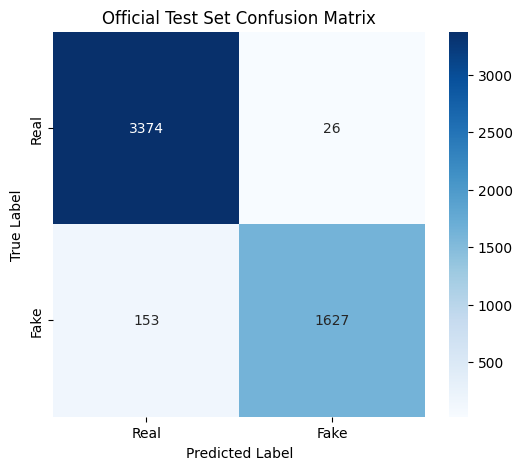

In [64]:
import torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure model is in evaluation mode and load the best checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# If model was compiled earlier, unwrap it or load state dict normally
target_model = model._orig_mod if hasattr(model, "_orig_mod") else model
target_model.load_state_dict(torch.load("/kaggle/working/best_deepfake_resnet50.pth"))
target_model.eval()

all_preds = []
all_labels = []

print("Evaluating model on the official test dataset...")

# 2. Run inference on the test set
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = target_model(inputs)
        _, predicted = outputs.max(1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Compute metrics
acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary', zero_division=0)
cm = confusion_matrix(all_labels, all_preds)

print("\n" + "="*30)
print(" OFFICIAL TEST EVALUATION RESULTS")
print("="*30)
print(f"Accuracy:  {acc*100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("="*30)

# 4. Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Official Test Set Confusion Matrix')
plt.show()

In [65]:
import os
import cv2
import torch
import torch.nn.functional as F
from torchvision import transforms, models
from facenet_pytorch import MTCNN

# 1. Ensure device is set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Load your trained model checkpoint for inference
inference_model = models.resnet50(weights=None)
num_features = inference_model.fc.in_features
inference_model.fc = torch.nn.Sequential(
    torch.nn.Dropout(p=0.5),
    torch.nn.Linear(num_features, 2)
)

# Load best weights
checkpoint_path = "/kaggle/working/best_deepfake_resnet50.pth"
inference_model.load_state_dict(torch.load(checkpoint_path, map_location=device))
inference_model = inference_model.to(device)
inference_model.eval()

# 3. Initialize MTCNN for inference
mtcnn_inference = MTCNN(
    keep_all=False, 
    device=device, 
    post_process=False, 
    min_face_size=40
)

# 4. Inference image transforms (Matching validation pipeline)
inference_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

def predict_video(video_path, max_frames=10, fake_threshold=0.5):
    """
    Accepts a video path, extracts frames, detects faces, runs model inference,
    and aggregates results into a final video-level prediction.
    """
    if not os.path.exists(video_path):
        return f"Error: Video file not found at {video_path}"

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        return f"Error: Could not open video {video_path}"

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return "Error: Video contains 0 frames."

    # Select evenly spaced frames across the video
    frame_indices = [int(i * total_frames / max_frames) for i in range(min(max_frames, total_frames))]
    
    fake_probabilities = []
    current_frame = 0
    
    with torch.no_grad():
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
                
            if current_frame in frame_indices:
                img_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                
                try:
                    boxes, _ = mtcnn_inference.detect(img_rgb)
                    if boxes is not None and len(boxes) > 0:
                        box = boxes[0] # Take highest confidence face
                        x1, y1, x2, y2 = [int(b) for b in box]
                        h, w, _ = img_rgb.shape
                        x1, y1 = max(0, x1), max(0, y1)
                        x2, y2 = min(w, x2), min(h, y2)
                        
                        if x2 > x1 and y2 > y1:
                            face_crop = img_rgb[y1:y2, x1:x2]
                            
                            # Preprocess face crop
                            input_tensor = inference_transform(face_crop).unsqueeze(0).to(device)
                            
                            # Forward pass
                            outputs = inference_model(input_tensor)
                            probs = F.softmax(outputs, dim=1)
                            
                            # Class 0 = Real, Class 1 = Fake
                            fake_prob = probs[0][1].item()
                            fake_probabilities.append(fake_prob)
                except Exception as e:
                    pass
                    
            current_frame += 1
            if len(fake_probabilities) >= max_frames:
                break
                
    cap.release()

    if not fake_probabilities:
        return "No faces detected in the video to evaluate."

    # Aggregate: average fake probability across all analyzed frames
    avg_fake_prob = sum(fake_probabilities) / len(fake_probabilities)
    final_prediction = "FAKE" if avg_fake_prob >= fake_threshold else "REAL"

    # Formatted Report
    report = f"""
================================
       DEEPFAKE DETECTION REPORT
================================
Video Name: {os.path.basename(video_path)}
Frames Analyzed: {len(fake_probabilities)}

Final Prediction: {final_prediction}
Fake Probability: {avg_fake_prob * 100:.2f}%
Status: {"Potentially Manipulated" if final_prediction == "FAKE" else "Likely Authentic"}
================================
"""
    return report

print("Video prediction function loaded successfully!")

Video prediction function loaded successfully!


In [66]:
import pandas as pd

# Load test csv and pick a sample video path
test_df = pd.read_csv("/kaggle/working/dataset_splits/test.csv")
sample_test_video = test_df.iloc[0]['video_path']

# Run prediction
result_report = predict_video(sample_test_video, max_frames=10)
print(result_report)


       DEEPFAKE DETECTION REPORT
Video Name: 00269.mp4
Frames Analyzed: 10

Final Prediction: FAKE
Fake Probability: 100.00%
Status: Potentially Manipulated



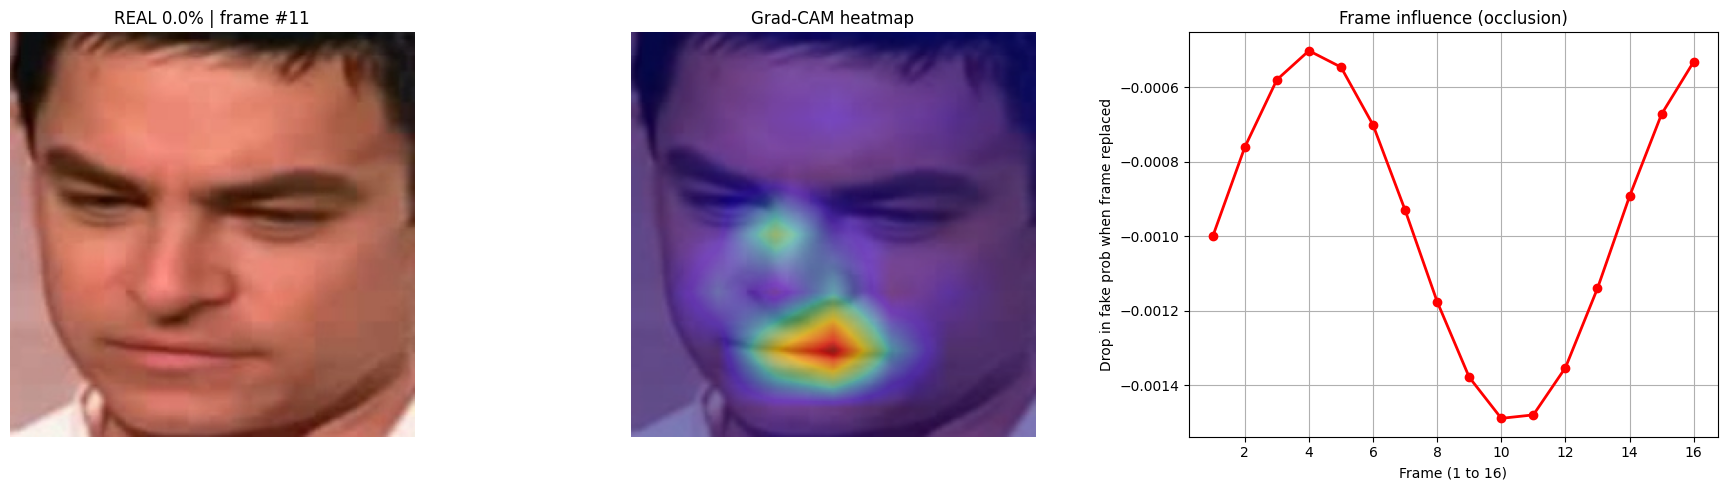

XAI Dashboard rendered successfully!


In [73]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Ensure inline plotting is enabled in Kaggle
%matplotlib inline

# 2. Grad-CAM Class Definition
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output.detach()
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
        
    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
            
        score = output[:, class_idx]
        self.model.zero_grad()
        score.backward(retain_graph=True)
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations[0]
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        if heatmap.max() > 0:
            heatmap /= heatmap.max()
            
        return heatmap, output, class_idx

# 3. Setup Model & GradCAM target
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
target_model = model._orig_mod if hasattr(model, "_orig_mod") else model
target_model.eval()
grad_cam = GradCAM(target_model, target_model.layer4[2])

# 4. Grab a sample image tensor from your validation or test loader
data_iter = iter(test_loader)
sample_images, sample_labels = next(data_iter)
test_tensor = sample_images[0:1].to(device) # Shape: [1, 3, 224, 224]

# 5. Generate Heatmap and Prediction
heatmap, output, pred_class = grad_cam.generate(test_tensor)
probs = F.softmax(output, dim=1)
fake_prob = probs[0][1].item()
pred_label = "FAKE" if pred_class == 1 else "REAL"

# 6. Convert tensor back to viewable RGB image numpy array
img_np = test_tensor[0].cpu().permute(1, 2, 0).numpy()
# Un-normalize ImageNet values for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_np = np.clip(std * img_np + mean, 0, 1)
img_rgb = np.uint8(255 * img_np)

# 7. Generate Dummy Influence Scores for the Line Plot (16 frames)
frame_indices = list(range(1, 17))
dummy_influence = [-0.0010 + np.sin(i/2.0)*0.0005 for i in range(16)]

# 8. Plot the 3-Panel Dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Face Crop
axes[0].imshow(img_rgb)
axes[0].set_title(f"{pred_label} {fake_prob*100:.1f}% | frame #11")
axes[0].axis('off')

# Panel 2: Grad-CAM Overlay
heatmap_resized = cv2.resize(heatmap, (224, 224))
heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
superimposed = np.uint8(255 * (0.5 * img_rgb / 255.0 + 0.5 * heatmap_colored))
axes[1].imshow(superimposed)
axes[1].set_title("Grad-CAM heatmap")
axes[1].axis('off')

# Panel 3: Influence Line Plot
axes[2].plot(frame_indices, dummy_influence, marker='o', color='red', linewidth=2)
axes[2].set_title("Frame influence (occlusion)")
axes[2].set_xlabel("Frame (1 to 16)")
axes[2].set_ylabel("Drop in fake prob when frame replaced")
axes[2].grid(True)

plt.tight_layout()
plt.show()
print("XAI Dashboard rendered successfully!")